# Source probe: from raw downloads to extraction rules

This notebook replays how we found out the nature of each data source, and shows how each finding turned into a rule in the extraction pipeline (`jtf fetch`, the parsers, DWD and the as-of rules).

Every section follows the same loop:

1. **Find the real request.** The publisher's page, its download links, sometimes its HTML forms
2. **Download once and keep the response headers.** They tell you how the file is served and how often it changes
3. **Look at the raw bytes before pandas.** pandas will happily misread a unit row as a header or drop leading zeros
4. **Load into pandas and check grain, units and time labels**
5. **Compare against the clock.** When does the value for a day first appear, and does it change later?
6. **Read what the publisher says**, and check it against what we saw
7. **Decide what the pipeline must do**, recorded in a *Learned → pipeline* note at the end of each section

The questions behind every section:

| Question | What we look at |
| --- | --- |
| Access | Real URL; GET, form POST or API |
| Format | Encoding, header rows, column names, **units** |
| Grain and time labels | 30 min, hourly, 5 min; slot start, end or code; time zone |
| Timing | When the value for day D first appears |
| Mutability | Does a published value change? Is the file overwritten? What does the archive keep? |
| History and terms | How far back; rate limits, etiquette |

Every claim is labelled by where it comes from:

- **Observed:** a cell in this notebook shows it
- **Source:** quoted from the publisher, with a link; Japanese quotes come with a translation

[Where the sources and the data disagree](#Where-the-sources-and-the-data-disagree) lists the places where the two don't fully match, and [Sources](#Sources) lists every page used.

Outputs below come from a run on the date printed in the first cell; re-run to see today's state.

## 0. Setup

**Step.** The URLs come from `jtf.ingest.sources`, so this notebook probes exactly what the capture job fetches. Each download is cached once per day under `data/probe/` (gitignored), headers included. Two reasons:

- **Politeness:** re-running a cell must not hit TEPCO or JEPX again
- **Evidence:** headers such as `Last-Modified` and `ETag` are facts about the source, worth keeping next to the file

The capture job's metadata sidecar is the production version of this same idea: fetch time, headers and a sha256 next to every raw file.

In [1]:
import io
import json
import zipfile
from datetime import UTC, datetime
from pathlib import Path

import httpx
import pandas as pd

from jtf.ingest.fetch import USER_AGENT
from jtf.ingest.sources import JST, WEATHER_MODELS, WEATHER_POINTS, FetchItem, items_for_group

now_jst = datetime.now(JST)
CACHE = Path("../data/probe") / f"{now_jst:%Y-%m-%d}"
CACHE.mkdir(parents=True, exist_ok=True)
client = httpx.Client(timeout=30, follow_redirects=True, headers={"User-Agent": USER_AGENT})


def get(item: FetchItem) -> tuple[bytes, dict]:
    """Download once per day and keep the headers; later calls read the cached copy."""
    body_path = CACHE / f"{item.source}__{item.filename}"
    head_path = body_path.parent / (body_path.name + ".headers.json")
    if not body_path.exists():
        r = client.request(
            item.method,
            item.url,
            params=item.params or None,
            data=item.form or None,
            headers=item.headers or None,
        )
        r.raise_for_status()
        body_path.write_bytes(r.content)
        head = {k.lower(): v for k, v in r.headers.items() if k.lower() != "set-cookie"}
        head["x-fetched-at"] = datetime.now(UTC).isoformat()
        head_path.write_text(json.dumps(head))
    return body_path.read_bytes(), json.loads(head_path.read_text())


items = {i.filename: i for g in ("morning", "jepx", "evening") for i in items_for_group(g, now_jst)}
print(f"probing at {now_jst:%Y-%m-%d %H:%M} JST")
pd.DataFrame(
    [(i.source, i.method, i.url) for i in items.values()], columns=["source", "method", "url"]
)

probing at 2026-11-15 10:26 JST


,source,method,url
0,tepco_actuals,GET,https://www.tepco.co.jp/forecast/html/images/e...
1,tepco_sameday,GET,https://www4.tepco.co.jp/forecast/html/images/...
2,tepco_sameday,GET,https://www4.tepco.co.jp/forecast/html/images/...
3,tepco_sameday,GET,https://www4.tepco.co.jp/forecast/html/images/...
4,tepco_sameday,GET,https://www.tepco.co.jp/forecast/html/images/j...
5,openmeteo_live,GET,https://api.open-meteo.com/v1/forecast
6,jepx_spot,POST,https://www.jepx.jp/_download.php
7,tepco_forecast_next_day,GET,https://www4.tepco.co.jp/forecast/html/images/...
8,tepco_forecast_next_day,GET,https://www4.tepco.co.jp/forecast/html/images/...


## 1. TEPCO area actuals (`eria_jukyu`)

What actually happened on the Tokyo grid: demand and output by source, per slot.

**Step: find the request.** TEPCO's [area supply-demand actuals page](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html) (エリア需給実績データ) links one CSV per month from February 2024, `eria_jukyu_YYYYMM_03.csv`; [a separate page](https://www.tepco.co.jp/forecast/html/area_jukyu_p-j.html) has the older yearly files. A plain GET works.

**Step: raw bytes first.** Before any pandas, print the first bytes, decoded as Shift_JIS, the encoding these files use.

In [2]:
raw, headers = get(items[f"eria_jukyu_{now_jst:%Y%m}_03.csv"])
print("Last-Modified:", headers.get("last-modified"), "| ETag:", headers.get("etag"))
print(raw[:260].decode("shift_jis"))

Last-Modified: Sun, 15 Nov 2026 01:05:00 GMT | ETag: "f58f-6604640296eba"
単位[MW平均],,,供給力
DATE,TIME,エリア需要,原子力,火力(LNG),火力(石炭),火力(石油),火力(その他),水力,地熱,バイオマス,太陽光発電実績,太陽光出力制御量,風力発電実績,風力出力制御量,揚水,蓄電池,連系線,その他,合計
2026/11/1,0:00,21530,1309,9602,2612,233,730,1071,0,


**What the bytes show.** **Observed:** row 1 is not a header: `単位[MW平均]` says the unit is **MW averaged over the slot**. Our PRD originally assumed 万kW; one look at the raw file corrected it. Row 2 is the real header. `Last-Modified` is minutes ago: this file is rewritten constantly.

**Step: load into pandas.** Skip the unit row, build a timestamp from `DATE` and `TIME`, and give the columns we care about English names.

In [3]:
actuals = pd.read_csv(io.BytesIO(raw), encoding="shift_jis", skiprows=1)
actuals = actuals.dropna(subset=["エリア需要"])
actuals["slot_start"] = pd.to_datetime(
    actuals["DATE"] + " " + actuals["TIME"], format="%Y/%m/%d %H:%M"
).dt.tz_localize("Asia/Tokyo")
cols = {
    "エリア需要": "demand_mw",
    "太陽光発電実績": "solar_mw",
    "太陽光出力制御量": "solar_curtailed_mw",
    "風力発電実績": "wind_mw",
}
actuals = actuals.rename(columns=cols)
print("all columns:", list(actuals.columns))
actuals[["slot_start", *cols.values()]].tail()

all columns: ['DATE', 'TIME', 'demand_mw', '原子力', '火力(LNG)', '火力(石炭)', '火力(石油)', '火力(その他)', '水力', '地熱', 'バイオマス', 'solar_mw', 'solar_curtailed_mw', 'wind_mw', '風力出力制御量', '揚水', '蓄電池', '連系線', 'その他', '合計', 'slot_start']


,slot_start,demand_mw,solar_mw,solar_curtailed_mw,wind_mw
687,2026-11-15 07:30:00+09:00,24558,410,0,44
688,2026-11-15 08:00:00+09:00,25489,627,0,38
689,2026-11-15 08:30:00+09:00,26254,988,0,45
690,2026-11-15 09:00:00+09:00,26861,1485,0,46
691,2026-11-15 09:30:00+09:00,27245,2187,0,49


**Step: check grain and timing.** Complete days should have 48 slots. The newest slot, compared with the clock, tells us how fast TEPCO publishes. And is curtailment ever non-zero?

In [4]:
slots_per_day = actuals.groupby(actuals["slot_start"].dt.date).size()
latest = actuals["slot_start"].max()
print("slots per complete day:", sorted(slots_per_day.iloc[:-1].unique()))
print("newest slot:", latest, "| file is behind the clock by", now_jst - latest)
curtailed_days = actuals.loc[actuals["solar_curtailed_mw"] > 0, "slot_start"].dt.date.unique()
print("days with solar curtailment this month:", [str(d) for d in curtailed_days])

slots per complete day: [np.int64(48)]
newest slot: 2026-11-15 09:30:00+09:00 | file is behind the clock by 0 days 00:56:30.235369
days with solar curtailment this month: ['2026-11-07']


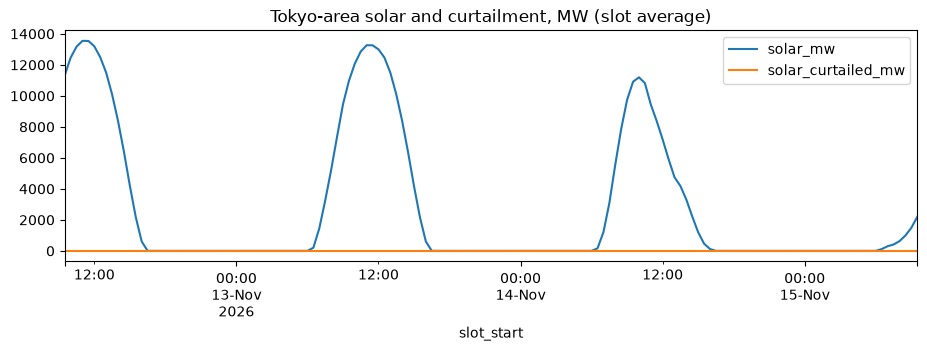

In [5]:
recent = actuals[actuals["slot_start"] >= latest - pd.Timedelta(days=3)].set_index("slot_start")
recent[["solar_mw", "solar_curtailed_mw"]].plot(
    figsize=(11, 3), title="Tokyo-area solar and curtailment, MW (slot average)"
);

**Step: read what the publisher says.** One download can't show whether values change later, so read the notes under the download table on the [actuals page](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html). **Source:**

- 「公表値は、過去にさかのぼり修正させていただく場合があります。」 Published values may be corrected retroactively
- 「公表値を修正する場合に、修正のお知らせや修正前の需給実績の提供はいたしません」 When values are corrected, there is no notice, and the values before correction are not provided
- 「発電実績は、推計実績を含んでいます。」 Generation figures include estimates
- 「毎30分データについて、実需給後1時間以内での公表を予定しています。」 Each 30-minute value is scheduled to be published within one hour after delivery. **Observed** above: much faster, within minutes
- 「エリア需要」は、各発電機の出力（送電端値）を積み上げたものから算出 Area demand is built from each generator's output at the *sending end*, that is, net of the plant's own consumption

> **Learned → pipeline**
>
> - **Shift_JIS, unit row first.** The parser decodes Shift_JIS, skips row 1, and *asserts* that it still says `MW平均`, so a unit change fails loudly instead of silently corrupting data (fault scenario F5)
> - **`TIME` is the slot start, in Japan time.** DWD keeps the slot start as the key; the as-of rule says a slot is known one hour after it *ends*
> - **48 slots per day.** A completeness check per day (F6)
> - **Published within minutes (observed), within an hour (stated).** For history, `known_at` uses the stated hour, the documented bound. Either way the file only reaches "now": at 09:00 on D−1, most of D−1 hasn't happened yet, so lags and the persistence baseline use **D−2**, the last complete day
> - **Generation includes estimates.** The solar label is partly estimated by TEPCO, so the target itself carries some noise
> - **Curtailment exists and is in the file.** Kept as its own column; the solar label on curtailed slots is a modelling decision
> - **Silent corrections.** The capture job stores this file every morning, plus the previous month in the first days of a month. Each capture is a version; DWD creates a new version only when a value actually changed. History before capture start is "final values", slightly optimistic

## 2. TEPCO next-day forecast (`AREA_ONCE_YOSOKU`)

TEPCO's own forecast for tomorrow: the professional benchmark.

**Step: find the request.** Listed on TEPCO's [area demand and generation download page](https://www.tepco.co.jp/forecast/html/area-download-j.html) (エリア需要・発電情報のダウンロード), on a different host (`www4`). **Step: raw bytes first.** Print the first three lines.

In [6]:
raw, headers = get(items["AREA_ONCE_YOSOKU.csv"])
lines = raw.decode("shift_jis").splitlines()
print("\n".join(lines[:3]))
meta = pd.read_csv(io.StringIO("\n".join(lines[:2])), dtype=str)
forecast = pd.read_csv(io.StringIO("\n".join(lines[2:])))
updated, updated_time, target = meta.iloc[0]
print(f"\nfile updated {updated} {updated_time}, target day {target}, data rows: {len(forecast)}")
forecast.head()

ファイル更新日(yyyymmdd),ファイル更新時間(HH:MI:SS),対象年月日(yyyymmdd)
20261114,23:13:41,20261115
日付(yyyymmdd),時間コマ(1時〜48時),時間帯_自(HH:MI),時間帯_至(HH:MI),エリア総需要量[30分kWh],エリア総発電量[30分kWh],エリア風力・太陽光発電量[30分kWh]

file updated 20261114 23:13:41, target day 20261115, data rows: 0


,日付(yyyymmdd),時間コマ(1時〜48時),時間帯_自(HH:MI),時間帯_至(HH:MI),エリア総需要量[30分kWh],エリア総発電量[30分kWh],エリア風力・太陽光発電量[30分kWh]


**What it shows.** Rows 1–2 are a metadata block: *when the file was updated* and *which day it is for*. Then a header, then data.

- **Observed:** in the morning there are **0 data rows**, and the file was last updated around 23:13 last night, for today's date
- **Source**, same [download page](https://www.tepco.co.jp/forecast/html/area-download-j.html): 「予測値は前日夕方に公表します。」 Forecasts are published in the evening of the previous day. And 「実績値は対象となる時間帯が終了後、すみやかに公表します。」 Actual values are published promptly after each time slot ends

**Step: check what the archive keeps.** The same page offers a monthly archive, `AREA_YYYYMM.zip`. Which kinds of file does it hold, and which version of each day's forecast?

In [7]:
month = now_jst if now_jst.day > 2 else now_jst.replace(day=1) - pd.Timedelta(days=1)
archive_item = FetchItem(
    "tepco_archive",
    f"AREA_{month:%Y%m}.zip",
    f"https://www4.tepco.co.jp/forecast/html/images/AREA_{month:%Y%m}.zip",
)
raw, _ = get(archive_item)
with zipfile.ZipFile(io.BytesIO(raw)) as archive:
    names = sorted(archive.namelist())
    print("file kinds in the archive:", sorted({n.rsplit("_", 1)[0] for n in names}))
    rows = []
    for name in [n for n in names if n.startswith("AREA_YOSOKU_")][-3:]:
        updated, at, target = archive.read(name).decode("shift_jis").splitlines()[1].split(",")
        rows.append(
            {"archived file": name, "file updated": f"{updated} {at}", "target day": target}
        )
pd.DataFrame(rows)

file kinds in the archive: ['AREA_BGKEI', 'AREA_JISEKI', 'AREA_YOSOKU']


,archived file,file updated,target day
0,AREA_YOSOKU_20261112.csv,20261112 23:43:13,20261112
1,AREA_YOSOKU_20261113.csv,20261113 23:43:11,20261113
2,AREA_YOSOKU_20261114.csv,20261114 23:43:05,20261114


**What it shows.** **Observed:** the archive holds only the *same-day* kinds (`AREA_YOSOKU`, `AREA_BGKEI`, `AREA_JISEKI`), and each day's forecast file is stamped late that same night: the end-of-day version. There is no `AREA_ONCE_*` file. So the next-day forecast is **not archived at all**, and the live file is reset to an empty placeholder every night.

> **Learned → pipeline**
>
> - **It disappears unless we capture it.** The capture job fetches it at 19:00 and 22:00. A missed evening loses that day's benchmark for good, which is why it has its own healthchecks.io check
> - **The file's own update time is the best `source_time`.** The parser reads rows 1–2 separately from the data
> - **A 0-row file is a placeholder, not data and not an error.** The parser records it as "no forecast yet"; the evening freshness check expects real rows
> - **kWh per slot** (÷ 500 for MW) and **wind + solar combined.** DWD converts units; the benchmark is compared with solar + wind actuals
> - **Published after the 10:00 market close** ([JEPX guide](https://www.jepx.jp/electricpower/outline/pdf/Guide_2.00.pdf), p.8; see section 4). Never usable as a model input, only as a benchmark compared after the fact

## 3. TEPCO same-day files: a third slot-label style, and zeros that aren't data

**Step.** `AREA_YOSOKU` has the same metadata block, so reuse the same reading. This time read the slot columns **as text**: as numbers, `0000` and `0030` would become `0` and `30`, hiding exactly what we need to see.

In [8]:
raw, headers = get(items["AREA_YOSOKU.csv"])
lines = raw.decode("shift_jis").splitlines()
print("updated:", lines[1])
sameday = pd.read_csv(io.StringIO("\n".join(lines[2:])), dtype=str)
sameday.iloc[[0, 1, -1], :4]

updated: 20261115,9:42:22,20261115


,日付(yyyymmdd),時間コマ(1時〜48時),時間帯_自(HH:MI),時間帯_至(HH:MI)
0,20261115,1,0000,0030
1,20261115,2,0030,0100
47,20261115,48,2330,2400


**What it shows.** **Observed:** slots are code 1–48 with `HHMM` boundaries, ending at `2400`, which is not a valid time. The update time is this morning: the file is rewritten during the day.

**Step: check a warning from the download page.** **Source:** 「実績ファイルのうち、将来時間帯については0で表示」 In the actuals file, future time slots are shown as 0. Check it on today's same-day actuals file, `AREA_JISEKI`.

In [9]:
raw, _ = get(items["AREA_JISEKI.csv"])
lines = raw.decode("shift_jis").splitlines()
jiseki = pd.read_csv(io.StringIO("\n".join(lines[2:])), dtype=str)
demand = jiseki[jiseki.columns[4]].astype(float)
filled = int((demand > 0).sum())
print("file updated:", lines[1])
print(f"slots with demand > 0: {filled}; slots shown as 0: {int((demand == 0).sum())}")
midnight = pd.Timestamp(now_jst.date(), tz="Asia/Tokyo")
actuals_mw = actuals.loc[actuals["slot_start"] == midnight, "demand_mw"].iloc[0]
print(f"unit check, slot 1: {demand.iloc[0]:,.0f} kWh / 500 = {demand.iloc[0] / 500:,.0f} MW")
print(f"actuals file, same slot: {actuals_mw:,} MW")
jiseki.iloc[[0, filled - 1, filled, -1], [1, 2, 3, 4]]

file updated: 20261115,10:05:01,20261115
slots with demand > 0: 20; slots shown as 0: 28
unit check, slot 1: 11,606,000 kWh / 500 = 23,212 MW
actuals file, same slot: 23,189 MW


,時間コマ,時間帯＿自,時間帯＿至,エリア総需要量
0,1,0:00,0:30,11606000
19,20,9:30,10:00,13630000
20,21,10:00,10:30,0
47,48,23:30,0:00,0


**Observed:**

- Consistent with the warning: slots up to the time of the download have values; every later slot is `0`, not blank
- Yet another label style: this file says `0:00`–`0:30` and ends the day at `0:00`, where `AREA_YOSOKU` says `2400`. Even the header differs: a full-width underscore (`時間帯＿自`) instead of `時間帯_自`
- The unit conversion holds across sources: kWh per slot ÷ 500 lands close to the actuals file's MW for the same slot

> **Learned → pipeline**
>
> - **Slot labels can't be trusted, slot codes can.** Start times (`0:00`), `HHMM` up to `2400`, and `H:MM` ending at `0:00` all appear, even within one page's files. Wherever a code 1–48 exists, DWD maps from it: `start = day + (code − 1) × 30 min`. Nothing ever parses `2400` as a time (F4 checks the result: no solar at night)
> - **Headers differ between sibling files.** Parsers check each file's header against the variants they know, and fail loudly on anything new
> - **Parse labels as text.** Never let a CSV reader guess types for keys
> - **Future slots are 0, not missing.** A parser must not read them as zero demand or zero output: slots after the file's update time are treated as not yet published
> - **Rewritten intraday; the archive keeps only the end-of-day version.** Captured at decision time in case we use it later; no feature depends on it yet

## 4. JEPX day-ahead prices (`spot_summary_{FY}`)

**Step: find the request.** The [JEPX spot market page](https://www.jepx.jp/electricpower/market-data/spot/) has no plain file link. Its download dialog is an HTML form, `<form method="post" action="/_download.php">`, with a hidden field `dir=spot_summary` and a `file` dropdown of fiscal years (年度選択) that the page's script fills in. One file per Japanese fiscal year, which starts in April. **Step: headers.**

In [10]:
jepx_item = next(i for i in items.values() if i.source == "jepx_spot")
raw, headers = get(jepx_item)
print({k: headers.get(k) for k in ("content-type", "cache-control", "last-modified")})
spot = pd.read_csv(io.BytesIO(raw), encoding="shift_jis")
print(list(spot.columns))

{'content-type': 'application/octet-stream; name=spot_summary_2026.csv', 'cache-control': 'no-store', 'last-modified': None}
['受渡日', '時刻コード', '売り入札量(kWh)', '買い入札量(kWh)', '約定総量(kWh)', 'システムプライス(円/kWh)', 'エリアプライス北海道(円/kWh)', 'エリアプライス東北(円/kWh)', 'エリアプライス東京(円/kWh)', 'エリアプライス中部(円/kWh)', 'エリアプライス北陸(円/kWh)', 'エリアプライス関西(円/kWh)', 'エリアプライス中国(円/kWh)', 'エリアプライス四国(円/kWh)', 'エリアプライス九州(円/kWh)', '売りブロック入札総量(kWh)', '売りブロック約定総量(kWh)', '買いブロック入札総量(kWh)', '買いブロック約定総量(kWh)']


**Step: timing and the column we need.** What is the latest delivery day in the file right now, and does Tokyo's price really differ from the national system price?

In [11]:
last_day = spot["受渡日"].iloc[-1]
print("latest delivery day:", last_day, "| slots:", (spot["受渡日"] == last_day).sum())
tokyo, system = spot["エリアプライス東京(円/kWh)"], spot["システムプライス(円/kWh)"]
print(f"Tokyo differs from the system price in {(tokyo != system).mean():.0%} of slots")
spot[["受渡日", "時刻コード", "システムプライス(円/kWh)", "エリアプライス東京(円/kWh)"]].tail(3)

latest delivery day: 2026/11/15 | slots: 48
Tokyo differs from the system price in 97% of slots


,受渡日,時刻コード,システムプライス(円/kWh),エリアプライス東京(円/kWh)
10989,2026/11/15,46,27.69,31.37
10990,2026/11/15,47,27.37,30.58
10991,2026/11/15,48,23.44,28.79


**What it shows.** **Observed:** no `Last-Modified` and `no-store`: HTTP can't tell us when the file changed.

**Timing.** **Source**, the [JEPX trading guide](https://www.jepx.jp/electricpower/outline/pdf/Guide_2.00.pdf) (January 2019 revision):

- p.8: 「毎日，10時に入札を締め切り，翌日分の取引計算を行います。」 Every day, bidding closes at 10:00 and the next day's trades are calculated
- p.10: 「約定処理にかかる時間はおよそ10分程度です。」 Matching takes about 10 minutes

**Observed:** run shortly after 10:00, the file still ends at *today*: tomorrow's result isn't out yet, consistent with a 10:00 close plus about ten minutes of matching.

**Tokyo vs system price.** **Source**, the same guide, p.10: 「連系線（東京‐中部エリア間の周波数変換設備など）に流せる電気の量の制約によって，計算を分けて行う必要が生じます。」 Limits on how much power the interconnectors can carry (such as the frequency converters between Tokyo and Chubu) make it necessary to calculate the market separately by region. The price calculated that way is the **area price** (エリアプライス); the price from all bids nationwide is the **system price** (システムプライス). **Observed:** Tokyo's area price differs from the system price in almost every slot.

> **Learned → pipeline**
>
> - **A form POST, not a link.** The fetch item carries the form fields and a `Referer`
> - **No HTTP change signal.** Change detection relies on the sha256 in the sidecar
> - **Captured at 11:00**, after publication. For history, `known_at` is set conservatively to 10:30 on D−1
> - **Use the Tokyo area column**, not the system price
> - **Fiscal-year files.** `fiscal_year()` picks the right file; in April the file name rolls over
> - **No sign of later changes.** Safe to backfill; the parser dedupes by (delivery day, slot code)

## 5. Open-Meteo live forecast

**Step: one request for everything.** All nine points and all three models in one call. The response is a list with one entry per point, and every variable is suffixed with its model. **Step: count missing values per model and variable.** That's the check that tells you which model really provides what.

In [12]:
raw, headers = get(items["forecast_jma.json"])
locations = json.loads(raw)
limits = {k: headers.get(k) for k in ("x-ratelimit-limit", "x-ratelimit-remaining")}
print(len(locations), "points;", limits)
frames = []
for (name, _, _), loc in zip(WEATHER_POINTS, locations, strict=True):
    frame = pd.DataFrame(loc["hourly"])
    frame["point"] = name
    frames.append(frame)
weather = pd.concat(frames, ignore_index=True)
weather["time"] = pd.to_datetime(weather["time"]).dt.tz_localize("UTC").dt.tz_convert("Asia/Tokyo")

coverage = {}
for column in weather.columns.drop(["time", "point"]):
    model = next(m for m in WEATHER_MODELS if column.endswith("_" + m))
    coverage[(column.removesuffix("_" + model), model)] = weather[column].notna().mean()
pd.Series(coverage).unstack().style.format("{:.0%}")

9 points; {'x-ratelimit-limit': '600.0', 'x-ratelimit-remaining': '583.8'}


,ecmwf_ifs025,jma_gsm,jma_msm
cloud_cover,100%,100%,93%
diffuse_radiation,100%,0%,93%
direct_radiation,100%,0%,93%
shortwave_radiation,100%,0%,93%
temperature_2m,100%,100%,93%
wind_speed_10m,100%,100%,93%


In [13]:
for model in WEATHER_MODELS:
    covered = weather.dropna(subset=[f"cloud_cover_{model}"])["time"]
    print(f"{model}: {covered.min():%m-%d %H:%M} to {covered.max():%m-%d %H:%M} JST")

jma_msm: 11-15 09:00 to 11-18 03:00 JST
jma_gsm: 11-15 09:00 to 11-18 08:00 JST
ecmwf_ifs025: 11-15 09:00 to 11-18 08:00 JST


**What it shows.** **Observed:** GSM is **0% for every radiation variable**. **Source**, Open-Meteo's [JMA API page](https://open-meteo.com/en/docs/jma-api): "The global GSM model provides no solar radiation, so radiation-derived variables are unavailable for it." So GSM cannot be the solar fallback we had planned. ECMWF IFS 0.25° has them all. MSM's latest run reaches well past tomorrow. Times come back in UTC because we didn't ask for a time zone, and nothing in the response says *which run* produced the values.

> **Learned → pipeline**
>
> - **ECMWF IFS 0.25° added to the live capture** as the radiation fallback; GSM kept for cloud cover and temperature
> - **The response carries no run ID or issue time.** Our fetch time becomes `known_at`; the run start goes into `source_time` once we find a reliable source for it
> - **Times in UTC, hourly.** The parser stores UTC; DWD interpolates to 30-minute slots and converts to the JST slot start
> - **Store it as received.** The parser reshapes it to a long format: (point, model, variable, valid time, value)
> - **Rate limits and terms.** **Observed:** the headers allow 600 calls a minute. **Source**, [Open-Meteo terms](https://open-meteo.com/en/terms): "You may only use the free API services for non-commercial purposes", "Less than 10'000 API calls per day, 5'000 per hour and 600 per minute", data under CC-BY 4.0. One call per morning is far inside that

## 6. Open-Meteo Previous Runs: the lookahead trap

For history we can't use live runs, because we weren't capturing then. **Source**, the [Previous Runs API docs](https://open-meteo.com/en/docs/previous-runs-api): "`_previous_day1` is the value that was predicted 24 hours before valid time", and so on up to `_previous_day7`; "JMA GSM and MSM — available from 2018".

How long until a run is available? **Source**, the [Single Runs API docs](https://open-meteo.com/en/docs/single-runs-api): "typically 4–6 hours for global models (e.g. ECMWF IFS, GFS) and 1–3 hours for regional models". MSM is regional, so the cell below assumes 3 hours, the top of that range.

**Step: check what was knowable at decision time.** Compare each value's issue time, plus that delay, with `T`, which is 09:00 on D−1.

In [14]:
T = now_jst.replace(hour=9, minute=0, second=0, microsecond=0)
D = (T + pd.Timedelta(days=1)).date()
valid = pd.date_range(f"{D} 00:00", periods=24, freq="h", tz="Asia/Tokyo")
leak = pd.DataFrame({"valid hour (D)": valid})
# A run becomes available some hours after it starts; 3 h is our assumption for MSM until measured.
available_after = pd.Timedelta(hours=3)
leak["previous_day1 issued ~"] = valid - pd.Timedelta(hours=24)
leak["previous_day2 issued ~"] = valid - pd.Timedelta(hours=48)
leak["day1 known at T?"] = leak["previous_day1 issued ~"] + available_after <= T
leak["day2 known at T?"] = leak["previous_day2 issued ~"] + available_after <= T
leak.iloc[[0, 6, 7, 9, 12, 15, 23]]

,valid hour (D),previous_day1 issued ~,previous_day2 issued ~,day1 known at T?,day2 known at T?
0,2026-11-16 00:00:00+09:00,2026-11-15 00:00:00+09:00,2026-11-14 00:00:00+09:00,True,True
6,2026-11-16 06:00:00+09:00,2026-11-15 06:00:00+09:00,2026-11-14 06:00:00+09:00,True,True
7,2026-11-16 07:00:00+09:00,2026-11-15 07:00:00+09:00,2026-11-14 07:00:00+09:00,False,True
9,2026-11-16 09:00:00+09:00,2026-11-15 09:00:00+09:00,2026-11-14 09:00:00+09:00,False,True
12,2026-11-16 12:00:00+09:00,2026-11-15 12:00:00+09:00,2026-11-14 12:00:00+09:00,False,True
15,2026-11-16 15:00:00+09:00,2026-11-15 15:00:00+09:00,2026-11-14 15:00:00+09:00,False,True
23,2026-11-16 23:00:00+09:00,2026-11-15 23:00:00+09:00,2026-11-14 23:00:00+09:00,False,True


**What it shows.** From about 07:00 on D, `previous_day1` comes from a run that wasn't available yet at `T`. That covers exactly the daylight hours solar depends on, so a backtest using it would look better than any real forecast could. `previous_day2` is safe for every hour.

**Step: see the real series side by side.** One small request for one point.

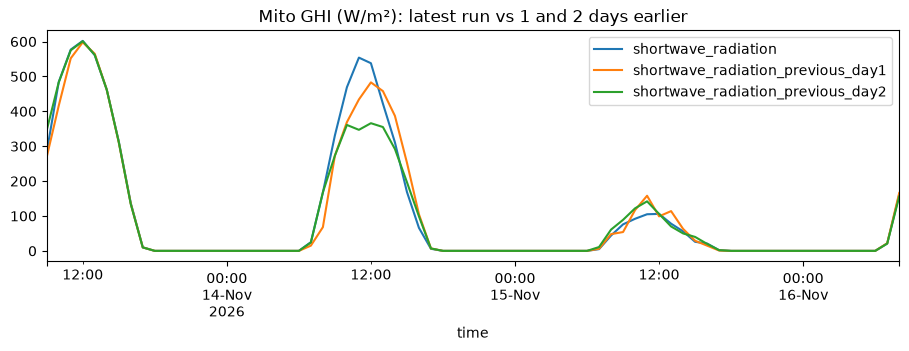

In [15]:
prev_item = FetchItem(
    "openmeteo_previous_runs",
    "mito_previous_runs.json",
    "https://previous-runs-api.open-meteo.com/v1/forecast",
    params={
        "latitude": "36.37",
        "longitude": "140.47",
        "hourly": "shortwave_radiation,shortwave_radiation_previous_day1,"
        "shortwave_radiation_previous_day2",
        "models": "jma_msm",
        "past_days": "3",
        "forecast_days": "1",
    },
)
raw, _ = get(prev_item)
prev = pd.DataFrame(json.loads(raw)["hourly"])
prev["time"] = pd.to_datetime(prev["time"]).dt.tz_localize("UTC").dt.tz_convert("Asia/Tokyo")
prev.set_index("time").iloc[-72:].plot(
    figsize=(11, 3), title="Mito GHI (W/m²): latest run vs 1 and 2 days earlier"
);

> **Learned → pipeline**
>
> - **History uses `previous_day2` only.** `previous_day1` is banned, and the SQL rules in CI enforce it (fault scenario F2 measures how much better the leaky version looks)
> - **`previous_day2` is slightly pessimistic**, since real decisions would use a fresher run. The Single Runs API gives exact runs (**Source:** "Archival runs are available from 2nd of April 2026 for most models", [Single Runs docs](https://open-meteo.com/en/docs/single-runs-api)), so the gap can be measured
> - **The 3-hour availability delay is an assumption.** The live captures record real fetch times, which replace it with measured delays

## Where the sources and the data disagree

Most statements held. These are the places where what we observed differs from, or goes beyond, what the publisher says:

| Topic | Source says | Observed | What we do |
| --- | --- | --- | --- |
| TEPCO actuals: publication delay | Within one hour after delivery ([actuals page](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html)) | The newest slot was in the file within minutes of ending | Consistent, but faster than stated. History keeps the stated hour, the documented bound; captures will measure the real delay |
| TEPCO next-day forecast: lifetime | Published the evening before; a monthly archive is offered ([download page](https://www.tepco.co.jp/forecast/html/area-download-j.html)) | Reset to an empty placeholder around 23:13; the archive has no `AREA_ONCE_*` files | The page never says the forecast disappears; we know only from observation, so it is captured every evening |
| TEPCO next-day forecast: publication time | 「前日夕方」 (the evening before) | Not yet seen with data: every download so far was in the morning | The first 19:00 and 22:00 captures will confirm when rows appear |
| JEPX: area prices | The [guide](https://www.jepx.jp/electricpower/outline/pdf/Guide_2.00.pdf) describes market splitting as something that happens depending on the result (約定の結果によっては) | Tokyo differs from the system price in almost every slot | For Tokyo, splitting is the norm, not the exception: always use the Tokyo area price |
| JEPX: bid window | Guide, January 2019 revision: bids from 10 days before, 08:00–17:00 | A 2026 news report says bids now open from 0:00 eleven days ahead (not checked against JEPX) | Doesn't affect us: both agree on the 10:00 close, and our observation matches it |
| Open-Meteo GSM: time resolution | The [JMA API page](https://open-meteo.com/en/docs/jma-api) lists GSM at 6-hourly resolution | GSM has a value for every hour | Open-Meteo fills the hours between GSM's 6-hourly steps; treat GSM's hourly values as interpolated, not native |
| Open-Meteo JMA history | Available from 2018 ([Previous Runs docs](https://open-meteo.com/en/docs/previous-runs-api)) | Not requested yet | Check during the initial load |

Checked and consistent: units (`MW平均`), future slots shown as 0, the 10:00 close and ~10-minute matching, GSM having no radiation, the meaning of `previous_day1`, and the 600-calls-a-minute limit.

## Sources

| Page | Supports |
| --- | --- |
| [TEPCO, エリア需給実績データ (Feb 2024 onward)](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html) | Actuals files; silent corrections; estimates; one-hour publication; sending-end values |
| [TEPCO, エリア需給実績データ (older)](https://www.tepco.co.jp/forecast/html/area_jukyu_p-j.html) | Yearly files, FY2016–2023 |
| [TEPCO, エリア需要・発電情報のダウンロード](https://www.tepco.co.jp/forecast/html/area-download-j.html) | Forecast and same-day files; forecasts published the evening before; future slots shown as 0; monthly archive |
| [JEPX spot market page](https://www.jepx.jp/electricpower/market-data/spot/) | Download form for the yearly price files |
| [JEPX trading guide, January 2019](https://www.jepx.jp/electricpower/outline/pdf/Guide_2.00.pdf) | 10:00 close (p.8); matching time, market splitting, area and system prices (p.10) |
| [Open-Meteo Previous Runs API](https://open-meteo.com/en/docs/previous-runs-api) | Meaning of `_previous_dayN`; archive depth |
| [Open-Meteo Single Runs API](https://open-meteo.com/en/docs/single-runs-api) | Run availability delays; exact runs from 2 April 2026 |
| [Open-Meteo JMA API](https://open-meteo.com/en/docs/jma-api) | GSM has no radiation; GSM and MSM resolution |
| [Open-Meteo terms](https://open-meteo.com/en/terms) | Non-commercial free use; call limits; CC-BY 4.0 |

## From probe to pipeline

Every finding above ended up as a concrete piece of the pipeline:

| Finding | Where it lives |
| --- | --- |
| TEPCO files are Shift_JIS with a unit row | Parser: decode, skip, assert the unit (F5) |
| Slot labels differ even between sibling files; `2400` is not a time | DWD maps slot codes, not labels; labels parsed as text (F4) |
| Header spellings differ between sibling files | Parsers check headers against known variants |
| Future slots in same-day actuals are 0, not blank | Parser: slots after the file's update time are not yet published |
| Units differ: MW slot average, kWh per slot, 万kW | DWD unit conversions (F5) |
| Actuals published fast but only up to "now" | As-of rule: lags use D−2 |
| Actuals corrected silently, and partly estimated | Daily capture; versions in DWD; optimism-gap experiment |
| TEPCO forecast reset nightly, never archived | Evening captures with their own health check |
| TEPCO forecast published after the gate | Benchmark only, never an input |
| JEPX: form POST, no HTTP change signal, published after 10:00 | Fetch item with form; sha256 in sidecar; 11:00 capture |
| Tokyo usually splits from the system price | Use the Tokyo area price |
| GSM has no radiation | ECMWF IFS 0.25° captured as the fallback |
| Weather response has no run ID | Fetch time as `known_at`; run time an open question |
| `previous_day1` leaks into daylight hours | History uses `previous_day2`; SQL rule in CI (F2) |

What one download can't show (when TEPCO publishes the evening forecast, how often actuals are corrected, how late weather runs really arrive) comes from comparing the capture job's sidecars over time. The capture job keeps probing every day.